# Phần 3 · Level Funnel & Churn Analysis
**Phân tích phễu người chơi & Tỷ lệ rời bỏ (Level 0 – 50)**

Notebook này chạy độc lập (tự tính lại các chỉ số phái sinh của Phần 2), gồm:

| Mục | Nội dung |
|---|---|
| 3.0 | Nạp dữ liệu & tính chỉ số (Churn, Retention, Win Rate, Attempts, level gai nhọn) |
| 3.1 | Biểu đồ 1 – Phễu người chơi (thang tuyến tính + thang log để lộ "khúc gãy") |
| 3.2 | Biểu đồ 2 – Level Churn Rate (cột, có ngưỡng bất thường) |
| 3.3 | Giai đoạn nhập môn: L0 (loading) và L1–L5 (tutorial) |
| 3.4 | Top Churn Levels + phân loại nguyên nhân nghi ngờ |
| 3.5 | Churn vs độ khó (Difficulty Spike) – Biểu đồ 3 |
| 3.6 | Churn theo giai đoạn game – Biểu đồ 4 |
| 3.7 | Insight tự động điền số liệu + khối tóm tắt để gửi lại |

> **Quy ước:** `Churn(L) = (Players(L) − Players(L+1)) / Players(L) × 100%` = tỷ lệ người chơi **rời đi sau khi ở level L**.
> Churn(0) là tỷ lệ rời đi trong lúc loading; Churn(50) không xác định (hết dữ liệu).

## 3.0 Thiết lập & nạp dữ liệu

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "font.size": 10,
})
C = dict(main="#2E5C8A", accent="#E8743B", bad="#C0392B", grey="#9AA5B1",
         light="#FBE3D2", tut="#DCE9F5", load="#E5E7EB")

OUT_DIR = Path("output_buoc3")
OUT_DIR.mkdir(exist_ok=True)

In [2]:
# =====================================================================
# 1. NẠP DỮ LIỆU
# =====================================================================
CSV_NAME = "DA_Test_02_game_analytics.csv"

# Tìm file ở thư mục hiện tại, nếu không thì ở thư mục chứa notebook
candidates = [Path(CSV_NAME), Path.cwd() / CSV_NAME]
DATA = next((p for p in candidates if p.exists()), None)
if DATA is None:
    raise FileNotFoundError(f"Không tìm thấy {CSV_NAME}")

df = pd.read_csv(DATA)

print(f"Đã nạp: {DATA.resolve()}")
print(f"Số dòng: {len(df)}   |   Số cột: {df.shape[1]}")
print(f"Level: {df['Level'].min()} → {df['Level'].max()}")

Đã nạp: C:\Users\Admin\Desktop\TestSonat6\DA_Test_02_game_analytics.csv
Số dòng: 51   |   Số cột: 6
Level: 0 → 50


### Chỉ số phái sinh (khớp định nghĩa Phần 2)
- **Churn %**: như công thức ở đầu notebook.
- **Retention %**: Players(L) / Players(0).
- **Win Rate**: Win_count / (Win_count + Lose_count), tính từ L2 (L1 chưa có dữ liệu thua).
- **Attempts/User**: (Win_count + Lose_count) / Players(L), tính từ L1 (L1 giả định Lose_count = 0 như Phần 2).
- **Level gai nhọn (spike)**: Lose_count ≥ 3 × trung vị Lose_count.

In [3]:
d = df.sort_values("Level").reset_index(drop=True).copy()

d["Players"]      = d["Drop_off_by_level"]
d["Lost"]         = d["Players"] - d["Players"].shift(-1)          # số người rời đi sau level L
d["Churn_pct"]    = d["Lost"] / d["Players"] * 100                 # NaN tại L50
d["Retention_pct"] = d["Players"] / d.loc[0, "Players"] * 100

win  = d["Win_count"]
lose = d["Lose_count"]
d["Win_rate_pct"]  = np.where(d["Level"] >= 2, win / (win + lose) * 100, np.nan)
d["Lose_rate_pct"] = 100 - d["Win_rate_pct"]
d["Attempts_per_user"] = np.where(d["Level"] >= 1, (win + lose.fillna(0)) / d["Players"], np.nan)

SPIKE_K = 3
spike_thr = SPIKE_K * d["Lose_count"].median()
d["Is_spike"] = d["Lose_count"] >= spike_thr

def phase(l):
    if l == 0:  return "L0 Loading"
    if l <= 5:  return "L1-5 Tutorial"
    if l <= 15: return "L6-15 Early"
    if l <= 30: return "L16-30 Mid"
    return "L31-50 Late"
PHASE_ORDER = ["L0 Loading", "L1-5 Tutorial", "L6-15 Early", "L16-30 Mid", "L31-50 Late"]
d["Phase"] = d["Level"].map(phase)

# Phạm vi có churn hợp lệ & phạm vi "level chơi" (bỏ loading) để làm baseline
ch   = d[d["Level"] <= 49].copy()                 # L0..L49 có Churn
play = d[(d["Level"] >= 1) & (d["Level"] <= 49)]  # L1..L49 (gameplay)

P0, P50 = d.loc[0, "Players"], d.loc[50, "Players"]
TOTAL_LOST = P0 - P50
mean_b, med_b, std_b = play["Churn_pct"].mean(), play["Churn_pct"].median(), play["Churn_pct"].std()
HIGH_THR = mean_b + std_b           # ngưỡng "cao vượt trội"

spike_levels = d.loc[d["Is_spike"], "Level"].tolist()
print(f"Người chơi: L0 = {P0:,} → L50 = {P50:,}  (mất {TOTAL_LOST:,} = {TOTAL_LOST/P0*100:.1f}%)")
print(f"Baseline churn L1–L49: TB = {mean_b:.2f}% | trung vị = {med_b:.2f}% | độ lệch chuẩn = {std_b:.2f}%")
print(f"Ngưỡng 'churn cao vượt trội' (TB + 1 SD) = {HIGH_THR:.2f}%")
print(f"Level gai nhọn (Lose_count ≥ {spike_thr:,.0f}): {spike_levels}")
d[["Level","Phase","Players","Lost","Churn_pct","Retention_pct","Win_rate_pct","Attempts_per_user","Is_spike"]].head(8)

Người chơi: L0 = 78,397 → L50 = 8,106  (mất 70,291 = 89.7%)
Baseline churn L1–L49: TB = 4.08% | trung vị = 3.75% | độ lệch chuẩn = 2.66%
Ngưỡng 'churn cao vượt trội' (TB + 1 SD) = 6.75%
Level gai nhọn (Lose_count ≥ 5,382): [22, 28, 29, 32, 34, 37, 42, 45]


,Level,Phase,Players,Lost,Churn_pct,Retention_pct,Win_rate_pct,Attempts_per_user,Is_spike
0,0,L0 Loading,78397,"14,714.00",18.77,100.00,NaN,NaN,False
1,1,L1-5 Tutorial,63683,"2,167.00",3.40,81.23,NaN,1.02,False
2,2,L1-5 Tutorial,61516,"1,778.00",2.89,78.47,99.37,1.04,False
3,3,L1-5 Tutorial,59738,"6,204.00",10.39,76.20,99.08,1.02,False
4,4,L1-5 Tutorial,53534,"4,650.00",8.69,68.29,98.58,1.05,False
5,5,L1-5 Tutorial,48884,"3,699.00",7.57,62.35,99.44,1.07,False
6,6,L6-15 Early,45185,"3,839.00",8.50,57.64,94.71,1.11,False
7,7,L6-15 Early,41346,"3,652.00",8.83,52.74,96.11,1.11,False


## 3.1 Biểu đồ 1 · Phễu người chơi (Player Funnel)

**Cách đọc**
- **(A) Thang tuyến tính:** nhìn độ dốc; đoạn nào "cắm đầu" = điểm thắt cổ chai. Vùng xám = loading (L0), vùng xanh = tutorial (L1–5).
- **(B) Thang log:** trên trục log, độ dốc tỷ lệ với **tỷ lệ** rời bỏ, nên level đầu (đông người) không còn "át" level sau. Đường đứt nét là phễu *lý tưởng* nếu churn đều ở mức trung bình hình học; điểm nào rơi **xuống dưới** đường này là đoạn mất người nhanh hơn mức đều.

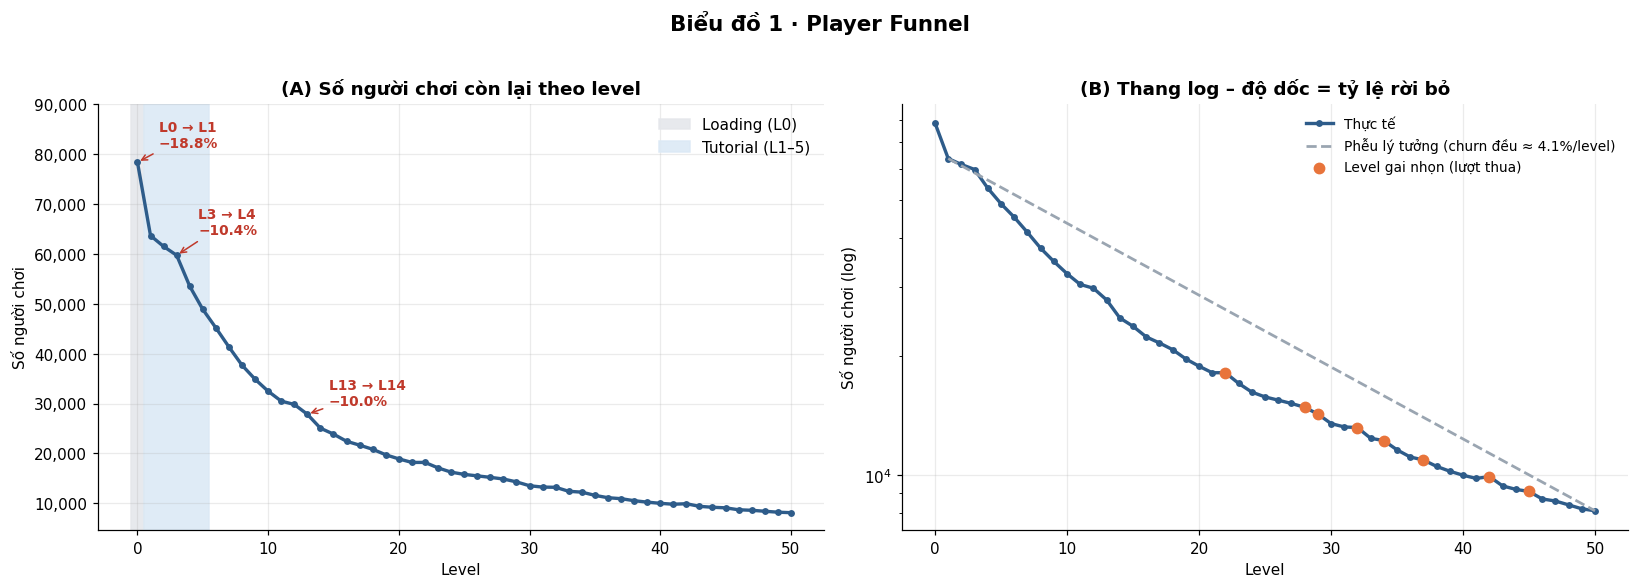

In [4]:
# Phễu lý tưởng: churn đều mỗi level từ L1 → L50 (trung bình hình học)
r_even = (d.loc[50, "Players"] / d.loc[1, "Players"]) ** (1 / 49)
churn_even = (1 - r_even) * 100
ref_line = d.loc[1, "Players"] * r_even ** (d["Level"] - 1)
ref_line[d["Level"] < 1] = np.nan

top3 = ch.nlargest(3, "Churn_pct")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# (A) tuyến tính
ax = axes[0]
ax.axvspan(-0.5, 0.5, color=C["load"], alpha=0.9, label="Loading (L0)")
ax.axvspan(0.5, 5.5, color=C["tut"], alpha=0.9, label="Tutorial (L1–5)")
ax.plot(d["Level"], d["Players"], color=C["main"], lw=2.2, marker="o", ms=3.5)
offsets = [(14, 10), (14, 14), (14, 6)]
for (_, row), off in zip(top3.iterrows(), offsets):
    ax.annotate(f"L{int(row.Level)} → L{int(row.Level)+1}\n−{row.Churn_pct:.1f}%",
                xy=(row.Level, row.Players), xytext=off, textcoords="offset points",
                fontsize=9, color=C["bad"], fontweight="bold",
                arrowprops=dict(arrowstyle="->", color=C["bad"]))
ax.set_ylim(top=d["Players"].max() * 1.15)
ax.set_title("(A) Số người chơi còn lại theo level")
ax.set_xlabel("Level"); ax.set_ylabel("Số người chơi")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(loc="upper right", frameon=False)

# (B) log
ax = axes[1]
ax.plot(d["Level"], d["Players"], color=C["main"], lw=2.2, marker="o", ms=3.5, label="Thực tế")
ax.plot(d["Level"], ref_line, color=C["grey"], ls="--", lw=1.8,
        label=f"Phễu lý tưởng (churn đều ≈ {churn_even:.1f}%/level)")
ax.scatter(spike_levels, d.set_index("Level").loc[spike_levels, "Players"],
           color=C["accent"], zorder=5, s=45, label="Level gai nhọn (lượt thua)")
ax.set_yscale("log")
ax.set_title("(B) Thang log – độ dốc = tỷ lệ rời bỏ")
ax.set_xlabel("Level"); ax.set_ylabel("Số người chơi (log)")
ax.legend(frameon=False, fontsize=9)

fig.suptitle("Biểu đồ 1 · Player Funnel", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(OUT_DIR / "bd1_player_funnel.png", bbox_inches="tight")
plt.show()

## 3.2 Biểu đồ 2 · Level Churn Rate

Dùng **% churn** thay vì số tuyệt đối để so sánh công bằng giữa các chặng.
- Đường đứt xanh: churn trung bình L1–L49 (không tính L0 để loading không kéo lệch baseline).
- Đường đứt cam: ngưỡng **TB + 1 SD**; cột vượt ngưỡng = "cao vượt trội".
- Cột đỏ = L0; cột cam = Top 5 level gameplay có churn cao nhất.

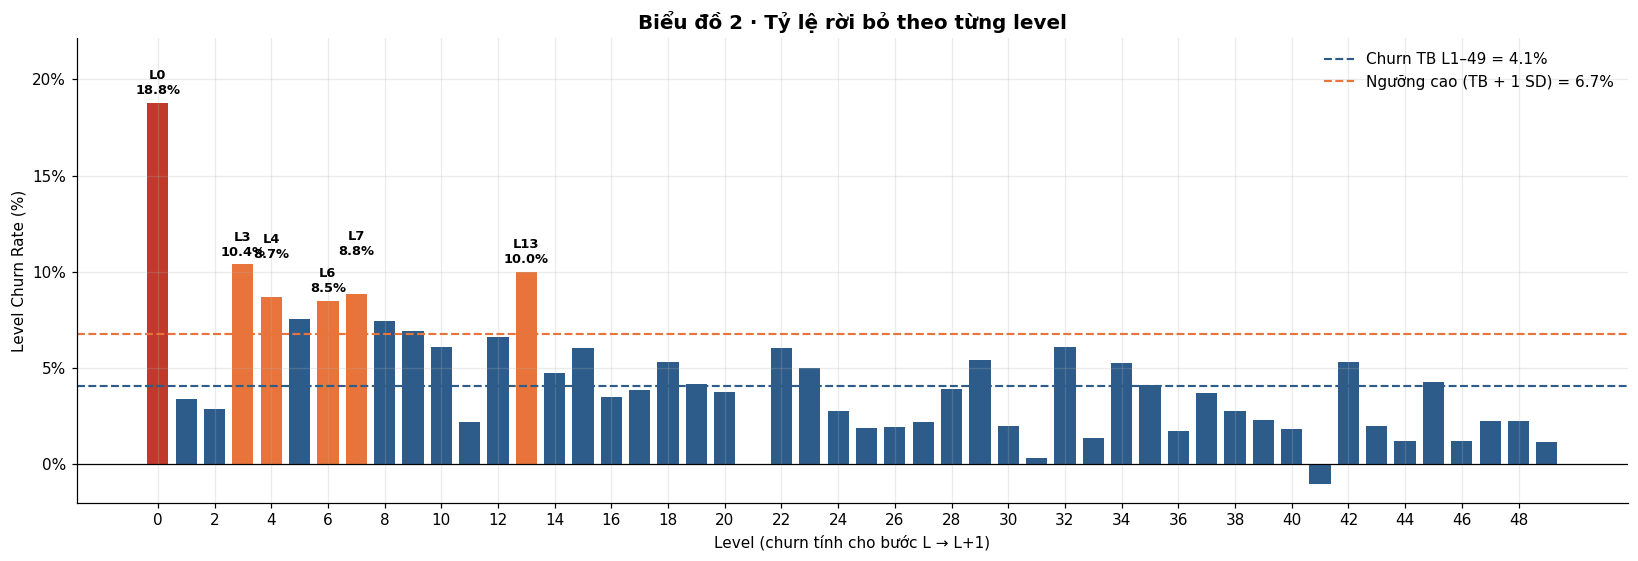

Số level gameplay vượt ngưỡng cao: 8/49 → [3, 4, 5, 6, 7, 8, 9, 13]

Lưu ý – churn âm (phễu tăng nhẹ so với level trước, có thể do người chơi quay lại / dữ liệu cộng dồn):
 Level  Players  Churn_pct
    21    18185      -0.03
    41     9798      -1.05


In [5]:
top5_play = play.nlargest(5, "Churn_pct")
top5_levels = set(top5_play["Level"])

colors = []
for l in ch["Level"]:
    if l == 0:               colors.append(C["bad"])
    elif l in top5_levels:   colors.append(C["accent"])
    else:                    colors.append(C["main"])

fig, ax = plt.subplots(figsize=(15, 5.2))
ax.bar(ch["Level"], ch["Churn_pct"], color=colors, width=0.75)
ax.axhline(mean_b,   color=C["main"],   ls="--", lw=1.4, label=f"Churn TB L1–49 = {mean_b:.1f}%")
ax.axhline(HIGH_THR, color=C["accent"], ls="--", lw=1.4, label=f"Ngưỡng cao (TB + 1 SD) = {HIGH_THR:.1f}%")
ax.axhline(0, color="black", lw=0.8)

prev_lv, bump = -9, 0
for _, row in pd.concat([ch[ch["Level"] == 0], top5_play]).sort_values("Level").iterrows():
    bump = 1.6 if (row.Level - prev_lv) <= 1 and bump == 0 else 0   # so le nhãn khi hai level liền kề
    ax.text(row.Level, row.Churn_pct + 0.3 + bump, f"L{int(row.Level)}\n{row.Churn_pct:.1f}%",
            ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    prev_lv = row.Level

ax.set_xticks(range(0, 50, 2))
ax.set_xlabel("Level (churn tính cho bước L → L+1)")
ax.set_ylabel("Level Churn Rate (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(min(-2, ch["Churn_pct"].min() - 0.5), ch["Churn_pct"].max() * 1.18)
ax.set_title("Biểu đồ 2 · Tỷ lệ rời bỏ theo từng level", fontsize=13, fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUT_DIR / "bd2_level_churn.png", bbox_inches="tight")
plt.show()

n_above = int((play["Churn_pct"] > HIGH_THR).sum())
print(f"Số level gameplay vượt ngưỡng cao: {n_above}/{len(play)} → {play.loc[play['Churn_pct']>HIGH_THR,'Level'].astype(int).tolist()}")
neg = ch.loc[ch["Churn_pct"] < 0, ["Level", "Players", "Churn_pct"]]
if len(neg):
    print("\nLưu ý – churn âm (phễu tăng nhẹ so với level trước, có thể do người chơi quay lại / dữ liệu cộng dồn):")
    print(neg.to_string(index=False))

## 3.3 Giai đoạn nhập môn (Early Onboarding: L0 – L5)

**A. Level 0 (loading)** – đối chiếu với ngưỡng cảnh báo 15–20%.
**B. Level 1–5 (tutorial)** – mức sụt giảm tích lũy, level nào là điểm nghẽn, và hành vi chơi (win rate, thời gian thắng) đi kèm.

In [6]:
# ---- A. Level 0 ----
c0, lost0 = d.loc[0, "Churn_pct"], int(d.loc[0, "Lost"])
if   c0 >= 20: verdict0 = "RẤT CAO, vượt ngưỡng 20%"
elif c0 >= 15: verdict0 = "CAO, nằm trong vùng cảnh báo 15–20%"
else:          verdict0 = "nằm trong ngưỡng chấp nhận (< 15%)"

print("A. LEVEL 0 → LEVEL 1 (LOADING)")
print(f"   Churn: {c0:.2f}%  ({lost0:,} / {P0:,} người)  → {verdict0}")
print(f"   Gấp {c0/mean_b:.1f} lần churn TB gameplay ({mean_b:.2f}%); gấp {c0/ch.loc[ch.Level>0,'Churn_pct'].max():.1f} lần đỉnh gameplay cao nhất")
print(f"   Chiếm {lost0/TOTAL_LOST*100:.1f}% tổng số người mất từ L0→L50")

# ---- B. Tutorial L1-L5 ----
tut = d[d["Level"].between(1, 5)].copy()
P1, P6 = d.loc[1, "Players"], d.loc[6, "Players"]
tut_lost = P1 - P6
print("\nB. TUTORIAL L1 → L5 (người rời đi sau L1..L5)")
print(f"   Mất {tut_lost:,} / {P1:,} người = {tut_lost/P1*100:.1f}% (churn TB {tut['Churn_pct'].mean():.1f}%/level)")
print(f"   Chiếm {tut_lost/TOTAL_LOST*100:.1f}% tổng người mất; TB các level còn lại (L6–L49) = {d[d.Level.between(6,49)]['Churn_pct'].mean():.1f}%/level")

tut_view = tut[["Level", "Players", "Lost", "Churn_pct", "Win_rate_pct", "Attempts_per_user",
                "Win_Play_time_s", "Lose_Play_time_s", "Is_spike"]].copy()
tut_view["Δ Win_time vs level trước (s)"] = d["Win_Play_time_s"].diff().loc[tut.index]
tut_view.rename(columns={"Churn_pct": "Churn %", "Win_rate_pct": "Win rate %"}, inplace=True)
tut_view

A. LEVEL 0 → LEVEL 1 (LOADING)
   Churn: 18.77%  (14,714 / 78,397 người)  → CAO, nằm trong vùng cảnh báo 15–20%
   Gấp 4.6 lần churn TB gameplay (4.08%); gấp 1.8 lần đỉnh gameplay cao nhất
   Chiếm 20.9% tổng số người mất từ L0→L50

B. TUTORIAL L1 → L5 (người rời đi sau L1..L5)
   Mất 18,498 / 63,683 người = 29.0% (churn TB 6.6%/level)
   Chiếm 26.3% tổng người mất; TB các level còn lại (L6–L49) = 3.8%/level


,Level,Players,Lost,Churn %,Win rate %,Attempts_per_user,Win_Play_time_s,Lose_Play_time_s,Is_spike,Δ Win_time vs level trước (s)
1,1,63683,"2,167.00",3.40,NaN,1.02,15.65,NaN,False,NaN
2,2,61516,"1,778.00",2.89,99.37,1.04,15.30,45.68,False,-0.35
3,3,59738,"6,204.00",10.39,99.08,1.02,33.59,76.67,False,18.29
4,4,53534,"4,650.00",8.69,98.58,1.05,46.36,66.56,False,12.77
5,5,48884,"3,699.00",7.57,99.44,1.07,31.47,69.21,False,-14.89


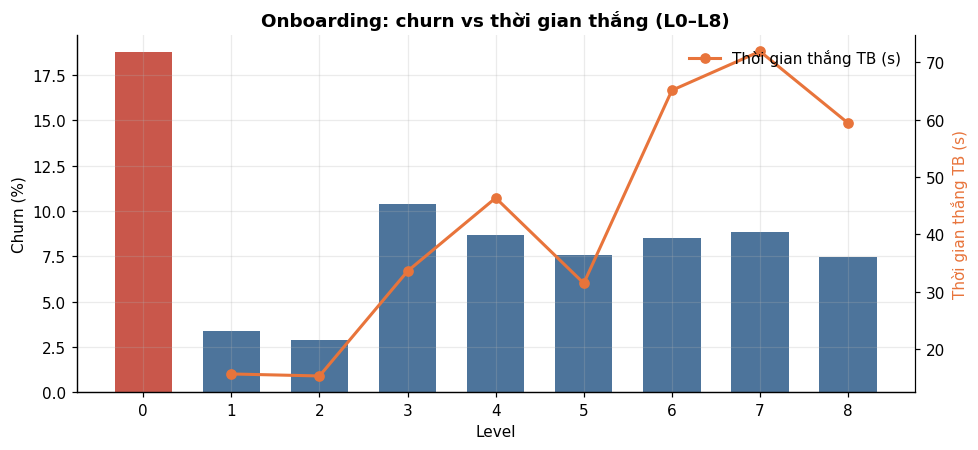

In [7]:
# Biểu đồ nhỏ: churn + thời gian thắng trong L0–L8 để xem 'điểm nghẽn' tutorial
sub = d[d["Level"] <= 8]
fig, ax1 = plt.subplots(figsize=(9, 4.2))
ax1.bar(sub["Level"], sub["Churn_pct"],
        color=[C["bad"] if l == 0 else C["main"] for l in sub["Level"]], alpha=0.85, width=0.65)
ax1.set_ylabel("Churn (%)"); ax1.set_xlabel("Level")
ax1.set_xticks(sub["Level"])
ax2 = ax1.twinx()
ax2.plot(sub["Level"], sub["Win_Play_time_s"], color=C["accent"], marker="o", lw=2, label="Thời gian thắng TB (s)")
ax2.set_ylabel("Thời gian thắng TB (s)", color=C["accent"]); ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax1.set_title("Onboarding: churn vs thời gian thắng (L0–L8)")
ax2.legend(loc="upper right", frameon=False)
plt.tight_layout()
fig.savefig(OUT_DIR / "bd_onboarding.png", bbox_inches="tight")
plt.show()

## 3.4 Định vị "Top Churn Levels"

Bảng Top 5 (gồm L0) và Top 5 **chỉ gameplay (L1+)**. Cột **Gợi ý nguyên nhân** là phân loại tự động *theo luật* (không phải kết luận nhân quả):

| Điều kiện | Nhãn |
|---|---|
| L0 | Loading / khởi động |
| L1–L5 | Onboarding / tutorial |
| Là level gai nhọn **hoặc** Win rate < 80% | Difficulty spike (độ khó) |
| Win rate ≥ 85% nhưng churn cao | Churn *không* do độ khó → nghi ngờ nội dung / cơ chế mới / nhịp game |
| Còn lại | Cần kiểm tra thêm |

In [8]:
def diagnose(r):
    l = int(r["Level"])
    if l == 0:  return "Loading / khởi động"
    if l <= 5:  return "Onboarding / tutorial"
    wr = r["Win_rate_pct"]
    if r["Is_spike"] or (pd.notna(wr) and wr < 80):
        return "Difficulty spike (độ khó)"
    if pd.notna(wr) and wr >= 85:
        return "Không do độ khó → nghi ngờ nội dung/cơ chế mới"
    return "Cần kiểm tra thêm"

cols = ["Level", "Phase", "Players", "Lost", "Churn_pct", "x_vs_TB", "Win_rate_pct",
        "Attempts_per_user", "Win_Play_time_s", "Is_spike", "Gợi ý nguyên nhân"]

def build_top(frame, n=5):
    t = frame.nlargest(n, "Churn_pct").copy()
    t["x_vs_TB"] = t["Churn_pct"] / mean_b
    t["Gợi ý nguyên nhân"] = t.apply(diagnose, axis=1)
    t["Level"] = t["Level"].astype(int)
    t["Lost"] = t["Lost"].astype(int)
    return t[cols].rename(columns={"Churn_pct": "Churn %", "Win_rate_pct": "Win rate %",
                                   "Attempts_per_user": "Attempts/User",
                                   "Win_Play_time_s": "Win time (s)", "x_vs_TB": "x so với TB"}).reset_index(drop=True)

top5_all  = build_top(ch)
top5_game = build_top(play)

print(">>> TOP 5 CHURN (gồm L0)")
display(top5_all)
print(">>> TOP 5 CHURN – CHỈ GAMEPLAY (L1–L49)")
display(top5_game)

>>> TOP 5 CHURN (gồm L0)


,Level,Phase,Players,Lost,Churn %,x so với TB,Win rate %,Attempts/User,Win time (s),Is_spike,Gợi ý nguyên nhân
0,0,L0 Loading,78397,14714,18.77,4.60,NaN,NaN,NaN,False,Loading / khởi động
1,3,L1-5 Tutorial,59738,6204,10.39,2.54,99.08,1.02,33.59,False,Onboarding / tutorial
2,13,L6-15 Early,27844,2787,10.01,2.45,87.87,1.28,81.33,False,Không do độ khó → nghi ngờ nội dung/cơ chế mới
3,7,L6-15 Early,41346,3652,8.83,2.16,96.11,1.11,71.92,False,Không do độ khó → nghi ngờ nội dung/cơ chế mới
4,4,L1-5 Tutorial,53534,4650,8.69,2.13,98.58,1.05,46.36,False,Onboarding / tutorial


>>> TOP 5 CHURN – CHỈ GAMEPLAY (L1–L49)


,Level,Phase,Players,Lost,Churn %,x so với TB,Win rate %,Attempts/User,Win time (s),Is_spike,Gợi ý nguyên nhân
0,3,L1-5 Tutorial,59738,6204,10.39,2.54,99.08,1.02,33.59,False,Onboarding / tutorial
1,13,L6-15 Early,27844,2787,10.01,2.45,87.87,1.28,81.33,False,Không do độ khó → nghi ngờ nội dung/cơ chế mới
2,7,L6-15 Early,41346,3652,8.83,2.16,96.11,1.11,71.92,False,Không do độ khó → nghi ngờ nội dung/cơ chế mới
3,4,L1-5 Tutorial,53534,4650,8.69,2.13,98.58,1.05,46.36,False,Onboarding / tutorial
4,6,L6-15 Early,45185,3839,8.50,2.08,94.71,1.11,65.13,False,Không do độ khó → nghi ngờ nội dung/cơ chế mới


In [9]:
# Kiểm tra giả thuyết "level mốc 10/20/30/40 là điểm nghẽn"
milestones = [10, 20, 30, 40]
ms = d[d["Level"].isin(milestones)][["Level", "Churn_pct", "Win_rate_pct", "Is_spike"]].copy()
ms["Hạng churn (1 = cao nhất, trong L1–49)"] = ms["Level"].map(
    play["Churn_pct"].rank(ascending=False, method="min").set_axis(play["Level"]))
ms["So với TB (điểm %)"] = ms["Churn_pct"] - mean_b
print(f"Churn TB các level mốc (10/20/30/40): {ms['Churn_pct'].mean():.2f}%   vs   TB L1–49: {mean_b:.2f}%")
non_ms = play[~play["Level"].isin(milestones)]["Churn_pct"]
print(f"Churn TB các level không phải mốc: {non_ms.mean():.2f}%")
ms.rename(columns={"Churn_pct": "Churn %", "Win_rate_pct": "Win rate %"})

Churn TB các level mốc (10/20/30/40): 3.42%   vs   TB L1–49: 4.08%
Churn TB các level không phải mốc: 4.14%


,Level,Churn %,Win rate %,Is_spike,"Hạng churn (1 = cao nhất, trong L1–49)",So với TB (điểm %)
10,10,6.10,98.68,False,10.00,2.02
20,20,3.75,94.40,False,25.00,-0.33
30,30,1.98,98.16,False,38.00,-2.10
40,40,1.84,98.45,False,41.00,-2.24


## 3.5 Churn vs Độ khó (Difficulty Spike)

Hai câu hỏi:
1. Level gai nhọn có kéo theo churn cao hơn level thường không? (so sánh nhóm + kiểm định Mann-Whitney)
2. Trong toàn bộ L2–L49, level có tỷ lệ thua cao hơn có churn cao hơn không? (Spearman, tính cả khi bỏ cụm onboarding L2–L9 để tránh nhiễu)

> ⚠️ Chỉ có ~50 quan sát tổng hợp → đây là **tương quan định hướng**, không phải nhân quả.

In [10]:
g = d[d["Level"].between(2, 49)].copy()   # có cả Win rate và Churn

spk, nrm = g[g["Is_spike"]], g[~g["Is_spike"]]
u = stats.mannwhitneyu(spk["Churn_pct"], nrm["Churn_pct"], alternative="greater")

print("SO SÁNH CHURN: level gai nhọn vs level thường (L2–L49)")
cmp_tbl = pd.DataFrame({
    "Số level": [len(spk), len(nrm)],
    "Churn TB %": [spk["Churn_pct"].mean(), nrm["Churn_pct"].mean()],
    "Churn trung vị %": [spk["Churn_pct"].median(), nrm["Churn_pct"].median()],
    "Win rate TB %": [spk["Win_rate_pct"].mean(), nrm["Win_rate_pct"].mean()],
    "Attempts/User TB": [spk["Attempts_per_user"].mean(), nrm["Attempts_per_user"].mean()],
}, index=["Gai nhọn", "Thường"])
display(cmp_tbl)
print(f"Mann-Whitney (gai nhọn > thường): U = {u.statistic:.0f}, p = {u.pvalue:.4f}")

rho_all, p_all = stats.spearmanr(g["Lose_rate_pct"], g["Churn_pct"])
g10 = g[g["Level"] >= 10]
rho_10, p_10 = stats.spearmanr(g10["Lose_rate_pct"], g10["Churn_pct"])
print(f"\nSpearman (Lose rate ~ Churn), L2–L49 : ρ = {rho_all:+.2f}, p = {p_all:.4f}  (n={len(g)})")
print(f"Spearman (Lose rate ~ Churn), L10–L49: ρ = {rho_10:+.2f}, p = {p_10:.4f}  (n={len(g10)})")

# Hiệu ứng trễ: churn sau level gai nhọn vs churn của chính level kế tiếp
nxt = d.set_index("Level")["Churn_pct"]
after = [nxt.get(l + 1) for l in spike_levels if (l + 1) in nxt.index and pd.notna(nxt.get(l + 1))]
print(f"\n(Lưu ý: Churn(L) đã là tỷ lệ rời đi SAU khi chơi level L, nên churn của chính level gai nhọn mới là 'cái giá' của level đó.)")
print(f"Để tham khảo – churn của level kế tiếp ngay sau level gai nhọn: TB {np.mean(after):.2f}% (vs TB L1–49 = {mean_b:.2f}%)")

SO SÁNH CHURN: level gai nhọn vs level thường (L2–L49)


,Số level,Churn TB %,Churn trung vị %,Win rate TB %,Attempts/User TB
Gai nhọn,8,5.00,5.27,73.33,1.99
Thường,40,3.92,2.83,93.93,1.45


Mann-Whitney (gai nhọn > thường): U = 217, p = 0.0597

Spearman (Lose rate ~ Churn), L2–L49 : ρ = +0.18, p = 0.2170  (n=48)
Spearman (Lose rate ~ Churn), L10–L49: ρ = +0.54, p = 0.0003  (n=40)

(Lưu ý: Churn(L) đã là tỷ lệ rời đi SAU khi chơi level L, nên churn của chính level gai nhọn mới là 'cái giá' của level đó.)
Để tham khảo – churn của level kế tiếp ngay sau level gai nhọn: TB 2.98% (vs TB L1–49 = 4.08%)


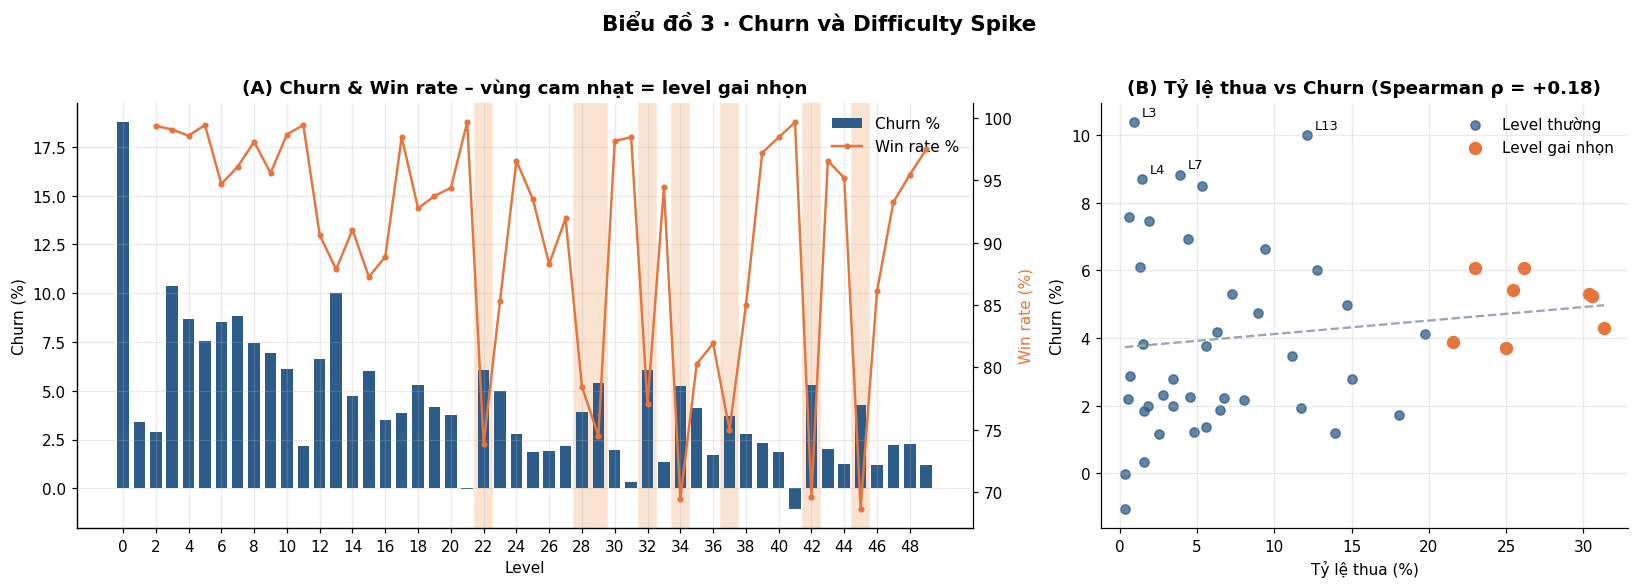

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})

# (A) churn theo level + vùng gai nhọn + win rate
ax = axes[0]
for l in spike_levels:
    ax.axvspan(l - 0.5, l + 0.5, color=C["light"], zorder=0)
ax.bar(ch["Level"], ch["Churn_pct"], color=C["main"], width=0.7, label="Churn %")
ax.set_ylabel("Churn (%)"); ax.set_xlabel("Level")
ax.set_xticks(range(0, 50, 2))
ax2 = ax.twinx()
ax2.plot(g["Level"], g["Win_rate_pct"], color=C["accent"], marker="o", ms=3, lw=1.6, label="Win rate %")
ax2.set_ylabel("Win rate (%)", color=C["accent"]); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("(A) Churn & Win rate – vùng cam nhạt = level gai nhọn")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", frameon=False)

# (B) scatter lose rate vs churn
ax = axes[1]
ax.scatter(nrm["Lose_rate_pct"], nrm["Churn_pct"], color=C["main"], alpha=0.75, label="Level thường")
ax.scatter(spk["Lose_rate_pct"], spk["Churn_pct"], color=C["accent"], s=60, label="Level gai nhọn")
for _, r in g.nlargest(4, "Churn_pct").iterrows():
    ax.annotate(f"L{int(r.Level)}", (r.Lose_rate_pct, r.Churn_pct), xytext=(5, 4), textcoords="offset points", fontsize=8.5)
m, b = np.polyfit(g["Lose_rate_pct"], g["Churn_pct"], 1)
xs = np.linspace(g["Lose_rate_pct"].min(), g["Lose_rate_pct"].max(), 50)
ax.plot(xs, m * xs + b, color=C["grey"], ls="--")
ax.set_xlabel("Tỷ lệ thua (%)"); ax.set_ylabel("Churn (%)")
ax.set_title(f"(B) Tỷ lệ thua vs Churn (Spearman ρ = {rho_all:+.2f})")
ax.legend(frameon=False)

fig.suptitle("Biểu đồ 3 · Churn và Difficulty Spike", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(OUT_DIR / "bd3_churn_vs_difficulty.png", bbox_inches="tight")
plt.show()

## 3.6 Churn theo giai đoạn game

So sánh **tỷ trọng số bước (level)** với **tỷ trọng người chơi bị mất** của từng giai đoạn. Giai đoạn nào "mất người nhiều hơn phần của nó" là nơi cần ưu tiên.

,Giai đoạn,Số bước,Người đầu giai đoạn,Người mất,Churn tích lũy %,Churn TB/level %,% tổng người mất,% số bước,"Hiệu số (mất − bước), điểm %"
0,L0 Loading,1,78397,14714,18.77,18.77,20.93,2.00,18.93
1,L1-5 Tutorial,5,63683,18498,29.05,6.59,26.32,10.00,16.32
2,L6-15 Early,10,45185,22755,50.36,6.74,32.37,20.00,12.37
3,L16-30 Mid,15,22430,9190,40.97,3.44,13.07,30.00,-16.93
4,L31-50 Late,19,13240,5134,38.78,2.53,7.30,38.00,-30.70


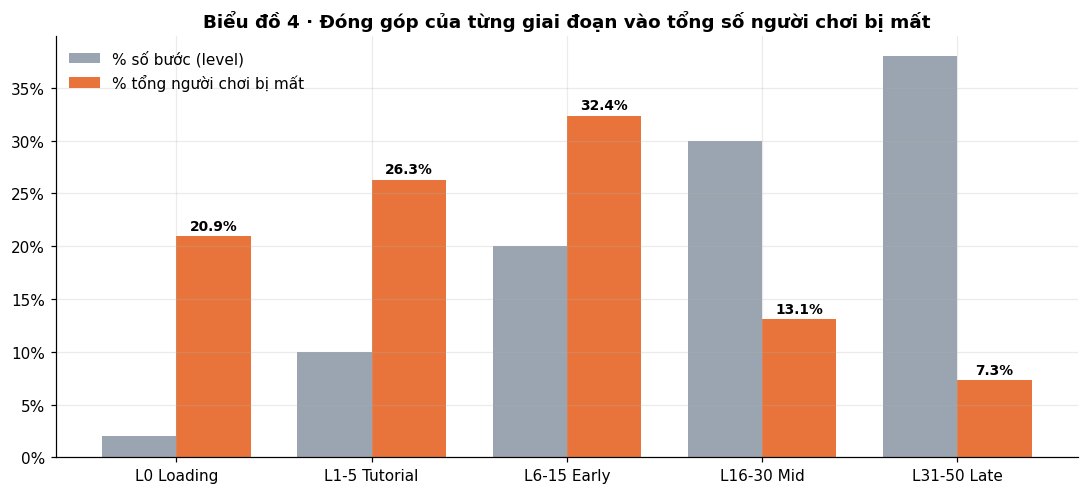

In [12]:
rows = []
for ph in PHASE_ORDER:
    s = ch[ch["Phase"] == ph]
    rows.append({
        "Giai đoạn": ph,
        "Số bước": len(s),
        "Người đầu giai đoạn": int(s["Players"].iloc[0]),
        "Người mất": int(s["Lost"].sum()),
        "Churn tích lũy %": s["Lost"].sum() / s["Players"].iloc[0] * 100,
        "Churn TB/level %": s["Churn_pct"].mean(),
        "% tổng người mất": s["Lost"].sum() / TOTAL_LOST * 100,
        "% số bước": len(s) / len(ch) * 100,
    })
phase_tbl = pd.DataFrame(rows)
phase_tbl["Hiệu số (mất − bước), điểm %"] = phase_tbl["% tổng người mất"] - phase_tbl["% số bước"]
display(phase_tbl)

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(phase_tbl)); w = 0.38
ax.bar(x - w/2, phase_tbl["% số bước"], w, color=C["grey"], label="% số bước (level)")
ax.bar(x + w/2, phase_tbl["% tổng người mất"], w, color=C["accent"], label="% tổng người chơi bị mất")
for i, v in enumerate(phase_tbl["% tổng người mất"]):
    ax.text(i + w/2, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(phase_tbl["Giai đoạn"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Biểu đồ 4 · Đóng góp của từng giai đoạn vào tổng số người chơi bị mất", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUT_DIR / "bd4_phase_contribution.png", bbox_inches="tight")
plt.show()

## 3.7 Insight tự động & khối tóm tắt

Cell dưới in ra các đoạn insight đã điền số liệu theo văn phong Product/Data Analyst, và lưu bảng + biểu đồ vào thư mục `output_buoc3/`.
Các câu **"nghi ngờ / gợi ý"** là giả thuyết, cần dữ liệu cấp người chơi hoặc A/B test để xác nhận.

In [13]:
tut_peak = tut.loc[tut["Churn_pct"].idxmax()]
tut_peak_dt = d["Win_Play_time_s"].diff().loc[tut_peak.name]
t0 = top5_game.iloc[0]
n_spike_in_top5 = int(top5_game["Is_spike"].sum())
ph = phase_tbl.set_index("Giai đoạn")

print("=" * 78)
print("INSIGHT 1 · ONBOARDING (LEVEL 0 – LEVEL 1)")
print("=" * 78)
print(f"Phân tích phễu cho thấy hiện tượng 'chảy máu' người chơi nghiêm trọng nhất diễn ra ngay ở bước "
      f"Loading → Level 1 với tỷ lệ rời bỏ {c0:.1f}% ({lost0:,} người) – mức {verdict0}, "
      f"và gấp {c0/mean_b:.1f} lần mức churn trung bình của các level chơi ({mean_b:.1f}%). "
      f"Vì Level 0 là thời gian tải game, rào cản gia nhập đến từ trải nghiệm khởi động "
      f"(tốc độ tải, lỗi khởi động, splash screen) chứ chưa hẳn do độ khó gameplay.")

print()
print("=" * 78)
print("INSIGHT 2 · TUTORIAL (LEVEL 1 – LEVEL 5)")
print("=" * 78)
print(f"Giai đoạn tutorial mất thêm {tut_lost/P1*100:.1f}% người chơi còn lại sau loading "
      f"(churn TB {tut['Churn_pct'].mean():.1f}%/level, so với {d[d.Level.between(6,49)]['Churn_pct'].mean():.1f}%/level ở L6–L49). "
      f"Điểm nghẽn là Level {int(tut_peak.Level)} ({tut_peak.Churn_pct:.1f}%), ")
if pd.notna(tut_peak_dt) and abs(tut_peak_dt) > 5:
    print(f"nơi thời gian thắng TB thay đổi {tut_peak_dt:+.1f}s so với level trước "
          f"({d.loc[tut_peak.name-1,'Win_Play_time_s']:.1f}s → {tut_peak['Win_Play_time_s']:.1f}s) trong khi win rate vẫn "
          f"{tut_peak['Win_rate_pct']:.1f}% – gợi ý một bước chuyển cơ chế/độ phức tạp chứ không phải level quá khó.")
else:
    print(f"không kèm thay đổi lớn về thời gian thắng; win rate {tut_peak['Win_rate_pct']:.1f}%.")

print()
print("=" * 78)
print("INSIGHT 3 · TOP CHURN LEVELS (GAMEPLAY)")
print("=" * 78)
lv_txt = ", ".join(f"L{int(r.Level)} ({r['Churn %']:.1f}%)" for _, r in top5_game.iterrows())
print(f"Top 5 level gameplay có churn cao nhất: {lv_txt}. Mức này gấp {top5_game['x so với TB'].min():.1f}–"
      f"{top5_game['x so với TB'].max():.1f} lần churn trung bình ({mean_b:.1f}%). "
      f"Trong 5 level này có {n_spike_in_top5} level là 'gai nhọn' về lượt thua; "
      f"{(top5_game['Level'] <= 15).sum()} level nằm trong 15 level đầu.")

print()
print("=" * 78)
print("INSIGHT 4 · MID/LATE GAME & DIFFICULTY SPIKE")
print("=" * 78)
sig = "có ý nghĩa thống kê" if u.pvalue < 0.05 else "chưa có ý nghĩa thống kê (p ≥ 0,05)"
print(f"Level gai nhọn có churn TB {spk['Churn_pct'].mean():.1f}% so với {nrm['Churn_pct'].mean():.1f}% ở level thường "
      f"(Mann-Whitney p = {u.pvalue:.3f} → {sig}). "
      f"Tương quan giữa tỷ lệ thua và churn là ρ = {rho_all:+.2f} (L2–L49) và ρ = {rho_10:+.2f} (L10–L49). ")
if rho_10 >= 0.3 and rho_all < 0.3:
    print("Chênh lệch giữa hai con số là đáng chú ý: ở toàn bộ L2–L49 tương quan yếu vì cụm onboarding (L3–L9) churn rất cao "
          "dù win rate gần 99% – tức churn giai đoạn đầu KHÔNG do độ khó. Từ L10 trở đi, tỷ lệ thua giải thích churn khá rõ: "
          "độ khó chỉ trở thành tác nhân chính ở mid/late game, nơi 'Difficulty Spike' chưa được cân bằng gây ức chế và đẩy người chơi rời đi.")
elif rho_all >= 0.3:
    print("Tương quan ở mức đáng kể xuyên suốt: level càng khó thì churn càng cao, củng cố giả thuyết 'Difficulty Spike' gây ức chế.")
else:
    print("Tương quan yếu: độ khó (tỷ lệ thua) không phải yếu tố giải thích chính cho churn; churn chủ yếu bị chi phối bởi vị trí trong phễu.")

late = play[play["Level"] >= 16].nlargest(3, "Churn_pct")
late_txt = ", ".join(f"L{int(r.Level)} ({r.Churn_pct:.1f}%{' – gai nhọn' if r.Is_spike else ''})" for _, r in late.iterrows())
print(f"Ở mid/late game (L16+), 3 level churn cao nhất: {late_txt}.")

print()
print("=" * 78)
print("INSIGHT 5 · GIẢ THUYẾT 'LEVEL MỐC 10/20/30/40'")
print("=" * 78)
print(f"Churn TB tại các level mốc là {ms['Churn_pct'].mean():.1f}% so với {non_ms.mean():.1f}% ở các level khác → "
      + ("không ủng hộ giả thuyết các mốc 10/20/30/40 là điểm nghẽn." if ms['Churn_pct'].mean() <= mean_b * 1.2
         else "có dấu hiệu các mốc là điểm nghẽn, cần xem từng level."))

print()
print("=" * 78)
print("INSIGHT 6 · PHÂN BỔ THEO GIAI ĐOẠN")
print("=" * 78)
for p in PHASE_ORDER:
    r = ph.loc[p]
    print(f"- {p:<14}: {r['% số bước']:>5.1f}% số bước  →  {r['% tổng người mất']:>5.1f}% tổng người mất "
          f"(churn tích lũy {r['Churn tích lũy %']:.1f}%)")
print(f"\nLoading + Tutorial (6 bước đầu, {ph.loc[['L0 Loading','L1-5 Tutorial'],'% số bước'].sum():.0f}% số bước) "
      f"chiếm {ph.loc[['L0 Loading','L1-5 Tutorial'],'% tổng người mất'].sum():.1f}% tổng người chơi bị mất.")

print()
print("GIỚI HẠN: dữ liệu tổng hợp theo level, không có ID người chơi/vật phẩm/tiền tệ → không kiểm chứng được "
      "giả thuyết thiếu booster/tiền; cần log cấp người chơi + A/B test để kết luận nhân quả.")

INSIGHT 1 · ONBOARDING (LEVEL 0 – LEVEL 1)
Phân tích phễu cho thấy hiện tượng 'chảy máu' người chơi nghiêm trọng nhất diễn ra ngay ở bước Loading → Level 1 với tỷ lệ rời bỏ 18.8% (14,714 người) – mức CAO, nằm trong vùng cảnh báo 15–20%, và gấp 4.6 lần mức churn trung bình của các level chơi (4.1%). Vì Level 0 là thời gian tải game, rào cản gia nhập đến từ trải nghiệm khởi động (tốc độ tải, lỗi khởi động, splash screen) chứ chưa hẳn do độ khó gameplay.

INSIGHT 2 · TUTORIAL (LEVEL 1 – LEVEL 5)
Giai đoạn tutorial mất thêm 29.0% người chơi còn lại sau loading (churn TB 6.6%/level, so với 3.8%/level ở L6–L49). Điểm nghẽn là Level 3 (10.4%), 
nơi thời gian thắng TB thay đổi +18.3s so với level trước (15.3s → 33.6s) trong khi win rate vẫn 99.1% – gợi ý một bước chuyển cơ chế/độ phức tạp chứ không phải level quá khó.

INSIGHT 3 · TOP CHURN LEVELS (GAMEPLAY)
Top 5 level gameplay có churn cao nhất: L3 (10.4%), L13 (10.0%), L7 (8.8%), L4 (8.7%), L6 (8.5%). Mức này gấp 2.1–2.5 lần churn trung bìn

In [14]:
# =====================================================================
# KHỐI TÓM TẮT – COPY TOÀN BỘ OUTPUT CỦA CELL NÀY GỬI LẠI CHO CLAUDE
# =====================================================================
print("##### SUMMARY_BUOC3 #####")
print(f"P0={P0}, P50={P50}, total_lost={TOTAL_LOST}")
print(f"baseline L1-49: mean={mean_b:.2f}, median={med_b:.2f}, std={std_b:.2f}, high_thr={HIGH_THR:.2f}")
print(f"churn_even_per_level={churn_even:.2f}")
print(f"L0: churn={c0:.2f}, lost={lost0}, share_total_lost={lost0/TOTAL_LOST*100:.1f}")
print(f"Tutorial L1-5: lost={tut_lost}, cum_churn={tut_lost/P1*100:.1f}, peak=L{int(tut_peak.Level)} {tut_peak.Churn_pct:.2f}")
print("Top5 (gồm L0):");    print(top5_all.round(2).to_string(index=False))
print("Top5 (gameplay):");  print(top5_game.round(2).to_string(index=False))
print("Milestones:");       print(ms.round(2).to_string(index=False))
print("Spike vs normal:");  print(cmp_tbl.round(2).to_string())
print(f"MannWhitney p={u.pvalue:.4f}; Spearman all={rho_all:+.2f} (p={p_all:.4f}); L10+={rho_10:+.2f} (p={p_10:.4f})")
print("Phase table:");      print(phase_tbl.round(2).to_string(index=False))
print("##### END #####")

# Lưu bảng
d.to_csv(OUT_DIR / "level_metrics_full.csv", index=False, encoding="utf-8-sig")
top5_all.to_csv(OUT_DIR / "top5_churn_all.csv", index=False, encoding="utf-8-sig")
top5_game.to_csv(OUT_DIR / "top5_churn_gameplay.csv", index=False, encoding="utf-8-sig")
phase_tbl.to_csv(OUT_DIR / "churn_by_phase.csv", index=False, encoding="utf-8-sig")
print(f"\nĐã lưu biểu đồ & bảng vào: {OUT_DIR.resolve()}")

##### SUMMARY_BUOC3 #####
P0=78397, P50=8106, total_lost=70291
baseline L1-49: mean=4.08, median=3.75, std=2.66, high_thr=6.75
churn_even_per_level=4.12
L0: churn=18.77, lost=14714, share_total_lost=20.9
Tutorial L1-5: lost=18498, cum_churn=29.0, peak=L3 10.39
Top5 (gồm L0):
 Level         Phase  Players  Lost  Churn %  x so với TB  Win rate %  Attempts/User  Win time (s)  Is_spike                              Gợi ý nguyên nhân
     0    L0 Loading    78397 14714    18.77         4.60         NaN            NaN           NaN     False                            Loading / khởi động
     3 L1-5 Tutorial    59738  6204    10.39         2.54       99.08           1.02         33.59     False                          Onboarding / tutorial
    13   L6-15 Early    27844  2787    10.01         2.45       87.87           1.28         81.33     False Không do độ khó → nghi ngờ nội dung/cơ chế mới
     7   L6-15 Early    41346  3652     8.83         2.16       96.11           1.11         71.92  